In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from feature_engine.outliers import Winsorizer
from sklearn.compose import ColumnTransformer
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

import joblib
import warnings
warnings.filterwarnings("ignore")

In [38]:
dataset = pd.read_csv("customer_segmentation.csv")

In [39]:
dataset.tail()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint
99995,SEG099996,37,Male,Ahmedabad,184607.0,15383.92,Platinum,25,68,2.93,...,NaN,1132,Medium,0.50,0.11,UPI,Desktop,Offline,4.2,Loyal Regular
99996,SEG099997,31,Female,Nagpur,565515.0,47126.25,Gold,56,438,7.78,...,Low,5293,High,0.36,0.19,Cash on Delivery,Tablet,Google Ads,3.9,Loyal Regular
99997,SEG099998,30,Male,Kolkata,827696.0,68974.67,Silver,29,136,5.23,...,NaN,2233,Medium,0.19,0.24,Cash on Delivery,Tablet,Organic Search,3.9,Loyal Regular
99998,SEG099999,18,Male,Delhi,834209.0,69517.42,Silver,6,22,2.10,...,Low,290,Low,0.00,0.07,Net Banking,Mobile,Offline,4.7,Occasional Buyer
99999,SEG100000,36,Male,Nagpur,467230.0,38935.83,Silver,3,25,6.13,...,Low,12,Low,0.19,0.37,Credit Card,Mobile,Offline,4.0,Budget Conscious


In [40]:
dataset.head()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint
0,SEG000001,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,...,NaN,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2,Budget Conscious
1,SEG000002,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,...,NaN,528,Low,0.18,0.14,UPI,Mobile,Email,2.8,At Risk
2,SEG000003,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,...,Low,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7,Loyal Regular
3,SEG000004,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,...,Low,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1,Occasional Buyer
4,SEG000005,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,...,NaN,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1,High Value


In [41]:
x = dataset.drop(["customer_id", "cluster_label_hint"], axis=1)
y = dataset.iloc[:, -1]

In [42]:
x.head()

,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,average_order_value,...,customer_support_calls,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating
0,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,822.39,...,1,NaN,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2
1,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,748.68,...,6,NaN,528,Low,0.18,0.14,UPI,Mobile,Email,2.8
2,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,2287.03,...,2,Low,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7
3,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,1501.70,...,1,Low,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1
4,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,3549.02,...,0,NaN,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1


In [43]:
y.head()

0    Budget Conscious
1             At Risk
2       Loyal Regular
3    Occasional Buyer
4          High Value
Name: cluster_label_hint, dtype: object

In [44]:
numeric_feature=x.select_dtypes(exclude=["object"]).columns
catag_feature=x.select_dtypes(include=["object"]).columns

In [45]:
numeric_feature

Index(['age', 'annual_income', 'monthly_income', 'tenure_months',
       'total_orders', 'purchase_frequency_monthly', 'average_order_value',
       'total_spend', 'discount_usage_rate', 'coupon_usage_count',
       'website_visits_monthly', 'app_usage_hours_weekly',
       'cart_abandonment_rate', 'days_since_last_purchase',
       'num_categories_purchased', 'return_rate', 'customer_support_calls',
       'loyalty_points', 'email_open_rate', 'ad_click_rate', 'review_rating'],
      dtype='object')

In [46]:
catag_feature

Index(['gender', 'city', 'membership_type', 'preferred_category',
       'complaint_level', 'loyalty_status', 'payment_method', 'device_type',
       'marketing_channel'],
      dtype='object')

In [47]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", Winsorizer(capping_method="iqr", tail="both", fold=1.5)),
    ("scaler", MinMaxScaler())
])

In [48]:
catag_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

In [49]:
preprocess_pipeline = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_feature),
    ("catag", catag_pipeline, catag_feature)
])

In [50]:
clean = preprocess_pipeline.fit(x)

In [51]:
Clean_data = pd.DataFrame(clean.transform(x))

In [52]:
Clean_data.head()

,0,1,2,3,4,5,6,7,8,9,...,46,47,48,49,50,51,52,53,54,55
0,0.16,0.185546,0.185546,0.120482,0.054503,0.230472,0.174511,0.014488,0.588235,0.149378,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.66,0.205398,0.205398,0.518072,0.078348,0.090487,0.153843,0.031491,0.104575,0.024896,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.24,0.623088,0.623088,0.578313,0.613157,0.562258,0.585179,0.587323,0.352941,0.821577,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.28,0.154218,0.154218,0.481928,0.076645,0.094354,0.364981,0.057165,0.196078,0.091286,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.72,0.326350,0.326350,0.746988,1.000000,0.832173,0.939026,1.000000,0.248366,1.000000,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [53]:
joblib.dump(clean, "dbscan_preprocess_pipeline.pkl")

['dbscan_preprocess_pipeline.pkl']

In [54]:
joblib.load("dbscan_preprocess_pipeline.pkl")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('catag', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. 

In [55]:
# model = DBSCAN(eps=3, min_samples=5)
# lables = model.fit_predict(Clean_data)

sample_data = Clean_data.sample(n=min(3000, len(Clean_data)), random_state=42)

for e in [0.3, 0.5, 0.7, 1.0]:
    model = DBSCAN(eps=e, min_samples=10, n_jobs=-1)
    labels = model.fit_predict(sample_data)
    print("eps:", e)
    print(np.unique(labels, return_counts=True))
    print()

eps: 0.3
(array([-1]), array([3000]))

eps: 0.5
(array([-1]), array([3000]))

eps: 0.7
(array([-1]), array([3000]))

eps: 1.0
(array([-1]), array([3000]))



In [56]:
dataset.head()

,customer_id,age,gender,city,annual_income,monthly_income,membership_type,tenure_months,total_orders,purchase_frequency_monthly,...,complaint_level,loyalty_points,loyalty_status,email_open_rate,ad_click_rate,payment_method,device_type,marketing_channel,review_rating,cluster_label_hint
0,SEG000001,26,Male,Nagpur,441099.0,36758.25,Gold,11,33,3.08,...,NaN,431,Low,0.29,0.21,Net Banking,Desktop,Offline,3.2,Budget Conscious
1,SEG000002,51,Male,Chennai,469034.0,39086.17,Gold,44,47,1.27,...,NaN,528,Low,0.18,0.14,UPI,Mobile,Email,2.8,At Risk
2,SEG000003,30,Male,Mumbai,1056803.0,88066.92,Silver,49,361,7.37,...,Low,6600,High,0.75,0.17,Net Banking,Tablet,Organic Search,3.7,Loyal Regular
3,SEG000004,32,Female,Kolkata,397014.0,33084.50,Platinum,41,46,1.32,...,Low,1005,Medium,0.43,0.07,Credit Card,Tablet,Referral,3.1,Occasional Buyer
4,SEG000005,54,Female,Bengaluru,639236.0,53269.67,Silver,63,686,10.86,...,NaN,20167,High,0.50,0.28,Net Banking,Mobile,Google Ads,4.1,High Value


In [57]:
print(labels)

[-1 -1 -1 ... -1 -1 -1]


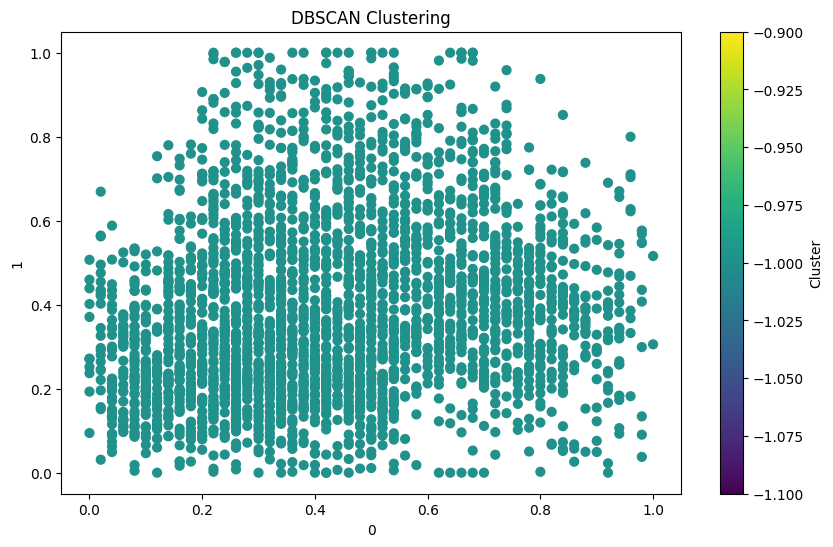

In [58]:
plt.figure(figsize=(10,6))

plt.scatter(
    sample_data.iloc[:, 0], 
    sample_data.iloc[:, 1],  
    c=labels,                 
    cmap='viridis',
    s=40
)

plt.title("DBSCAN Clustering")
plt.xlabel(sample_data.columns[0])
plt.ylabel(sample_data.columns[1])

plt.colorbar(label="Cluster")
plt.show()

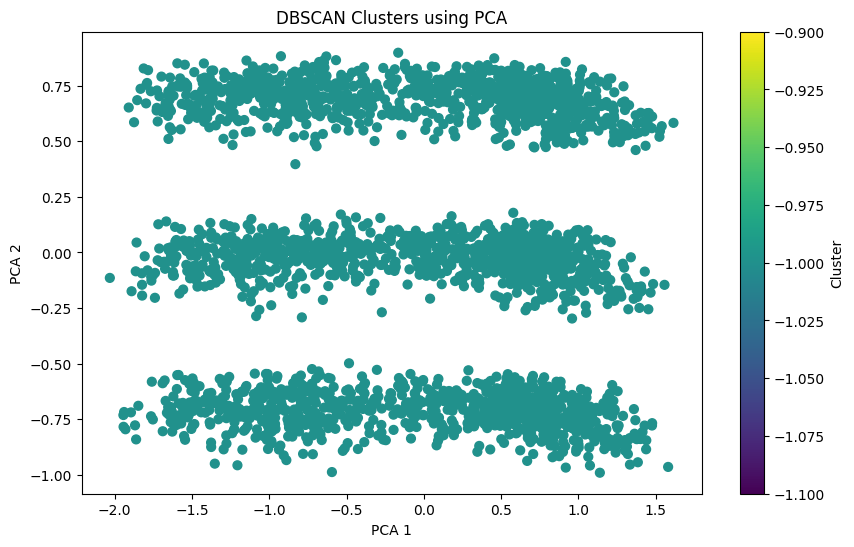

In [59]:
# Reduce dimensions to 2D
pca = PCA(n_components=2)

pca_data = pca.fit_transform(sample_data)

# Scatter Plot
plt.figure(figsize=(10,6))

plt.scatter(
    pca_data[:,0],
    pca_data[:,1],
    c=labels,
    cmap='viridis',
    s=40
)

plt.title("DBSCAN Clusters using PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")

plt.colorbar(label="Cluster")
plt.show()

In [60]:
joblib.dump(model, "dbscan_model.pkl")

['dbscan_model.pkl']

In [61]:
sample_customer = {
    "age": 35,
    "gender": "Female",
    "city": "Pune",
    "annual_income": 1200000,
    "monthly_income": 100000,
    "membership_type": "Gold",
    "tenure_months": 48,
    "total_orders": 180,
    "purchase_frequency_monthly": 7.5,
    "average_order_value": 3200,
    "total_spend": 520000,
    "discount_usage_rate": 0.12,
    "coupon_usage_count": 15,
    "website_visits_monthly": 40,
    "app_usage_hours_weekly": 9,
    "cart_abandonment_rate": 0.15,
    "days_since_last_purchase": 5,
    "preferred_category": "Electronics",
    "num_categories_purchased": 6,
    "return_rate": 0.05,
    "customer_support_calls": 1,
    "complaint_level": "Low",
    "loyalty_points": 5200,
    "loyalty_status": "High",
    "email_open_rate": 0.65,
    "ad_click_rate": 0.22,
    "payment_method": "Credit Card",
    "device_type": "Mobile",
    "marketing_channel": "Instagram",
    "review_rating": 4.6
}

In [62]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np

# Create dataframe
sample_df = pd.DataFrame([sample_customer])

# Transform sample customer
sample_transformed = preprocess_pipeline.transform(sample_df)

# Fit nearest neighbor model on DBSCAN trained data
nn = NearestNeighbors(n_neighbors=1)

nn.fit(sample_data)

# Find nearest data point
distance, index = nn.kneighbors(sample_transformed)

# Get cluster label
predicted_cluster = labels[index[0][0]]

print("Predicted Cluster:", predicted_cluster)
print("Distance:", distance[0][0])

Predicted Cluster: -1
Distance: 1.7752706217252752
